# Lab 4: Enhancing the Bike Sharing System

Welcome to **Lab 4** of the Modeling & Simulation course! In this laboratory session, we will build upon the foundations laid in the previous labs to enhance our bike-sharing system simulation. This lab introduces the concept of **time slot-specific probabilities**, allowing you to model varying bike usage patterns throughout the day. Additionally, you will implement bike maintenance and downtime, develop a rebalancing mechanism, track customer satisfaction, and undertake a **graded assignment** to design and implement a comprehensive simulation project.

---

## Table of Contents

1. [Recap of Previous Labs](#recap)
2. [Introduction to Time Slot-Specific Probabilities](#time-slots)
   - [Understanding Time Slots](#understanding-time-slots)
3. [Implementing Time Slot-Specific Probabilities](#implementing-time-slots)
   - [Defining Time Slots](#defining-time-slots)
4. [Graded Assignment Overview](#assignment)

---

## <a name="recap"></a>1. Recap of Previous Labs

### Lab 1: Python Introduction
- Gained proficiency in Python programming.
- Learned fundamental programming concepts such as variables, data types, control structures, functions, and basic I/O operations.

### Lab 2: Basic Bike Sharing System Modeling
- Developed a simplified bike-sharing system using Python classes.
- Modeled entities such as stations, bikes, and trips.
- Implemented basic trip generation and analyzed system behavior over a short period.

### Lab 3: Introduction to SimPy
- Introduced SimPy, a discrete-event simulation library in Python.
- Reimplemented the bike-sharing system using SimPy constructs like environments, processes, and resources.
- Explored extensions including variable trip durations, rebalancing strategies, and customer satisfaction tracking.

---

## <a name="time-slots"></a>2. Introduction to Time Slot-Specific Probabilities

In real-world scenarios, bike usage varies throughout the day. To simulate this variability, we introduce **time slot-specific probabilities**. This enhancement allows the simulation to reflect different demand levels during various periods, such as morning rush hours and midday.

### <a name="understanding-time-slots"></a>Understanding Time Slots

- **Time Slots:** Defined periods within a day where bike trip probabilities differ.
- **Recurring Pattern:** Time slots repeat every simulated day, enabling multi-day simulations.
- **Example Time Slots:**
  - **Morning Start (0-120 minutes):** Initial hours with increasing demand.
  - **Midday (120-720 minutes):** Peak hours with stable high demand.

### <a name="mapping-time"></a>Mapping Simulation Time to Real-Time

To create realistic simulations, map simulation minutes to actual day times.

- **Simulation Start Time:** 6:00 AM
- **Morning Start:** 6:00 AM - 8:00 AM (0-120 minutes)
- **Midday:** 8:00 AM - 6:00 PM (120-720 minutes)
- **Simulation Duration:** 20 days (12 hours/day) → 14400 minutes

---

## <a name="implementing-time-slots"></a>3. Implementing Time Slot-Specific Probabilities

### <a name="defining-time-slots"></a>Defining Time Slots

Define time slots with specific trip probability matrices within a single day. Use the modulo operation to map the current simulation time to the appropriate time slot.

```python
# Define time slots for a single day
time_slots = [
    {
        'name': 'morning_start',
        'start': 0,       # 0 minutes into the day (6:00 AM)
        'end': 120,       # 2 hours
        'prob_matrix': {
            ('A', 'B'): 0.4,
            ('B', 'A'): 0.6,
            ('A', 'C'): 0.2,
            ('C', 'A'): 0.5,
            ('B', 'C'): 0.3,
            ('C', 'B'): 0.4,
            ('A', 'D'): 0.3,
            ('D', 'A'): 0.2,
        }
    },
    {
        'name': 'midday',
        'start': 120,      # 2 hours into the day (8:00 AM)
        'end': 720,        # 12 hours total (6:00 PM)
        'prob_matrix': {
            ('A', 'B'): 0.2,
            ('B', 'A'): 0.3,
            ('A', 'C'): 0.1,
            ('C', 'A'): 0.2,
            ('B', 'C'): 0.25,
            ('C', 'B'): 0.35,
            ('A', 'D'): 0.15,
            ('D', 'A'): 0.25,
        }
    }
    # Add more time slots if needed
]

# Define default probability matrix if no slot matches
default_prob_matrix = {
    ('A', 'B'): 0.05,
    ('B', 'A'): 0.05,
    ('A', 'C'): 0.05,
    ('C', 'A'): 0.05,
    ('B', 'C'): 0.05,
    ('C', 'B'): 0.05,
    ('A', 'D'): 0.05,
    ('D', 'A'): 0.05,
}


In [39]:
# Start from the code you've implemented in lab 3, add time-slot specific probabilities below


## <a name="assignment"></a>Graded Assignment Overview

Design and implement an enhanced bike-sharing system simulation using **SimPy**, incorporating advanced features to model a realistic and complex environment. Your simulation should build upon the concepts learned in previous labs and include the following components:

---

Your simulation must include the following elements:

### 1. Multiple Stations:

- **Minimum of Four stations** with varying capacities and initial bike counts.
- Each station should have a unique name, capacity, and initial number of bikes.

### 2. Time-Dependent Trip Probabilities:

- Implement trip probabilities that change based on different time slots (e.g., morning start, midday).
- Define at least **two distinct time slots** with different probability matrices.
- Ensure that time slots are **recurring daily** over the simulation period.

### 3. Bike Maintenance and Downtime:

- Model bike failures with a specified failure probability during trips.
- Implement a repair process that handles broken bikes, making them unavailable until repaired. The implementation details are up to your imagination.
- Track and report the number of bikes under maintenance.

### 4. Rebalancing Mechanism:

- Develop a rebalancing strategy to redistribute bikes between stations based on current demand and bike levels.
- Rebalancing should occur at regular intervals (e.g., every 20 minutes) and follow defined criteria.

### 5. Customer Satisfaction Tracking:

- Track the number of **unhappy customers** who cannot rent a bike due to unavailability.
- Track the number of **unhappy customers** who cannot return a bike due to full stations.

### 6. Data Collection and Visualization:

- Collect data on **bike levels** at each station over time.
- Collect data on **broken bikes** and maintenance activities.
- Collect data on **customer satisfaction** metrics.
- Generate plots to visualize:
  - **Bike levels** at each station over time.
  - **Number of bikes under maintenance**.
  - **Customer satisfaction metrics** (e.g., unhappy customers over time).

### 7. Simulation:

- Allow the simulation to run for a configurable duration (e.g., **20 days**).
- Parameters such as the number of stations, capacities, initial bikes, trip probabilities, maintenance rates, rebalancing intervals, and simulation duration should be easily adjustable.
- Simulate and observe the system with various parameters.

---

#### (Optional) Money Earning Mechanism:

- Introduce a system where the bike-sharing service earns **money based on bike rentals** (e.g., per hour rented).
- Track and report **total earnings** over the simulation period.

## What to Look For in Your Simulations

The primary objective of this lab is to enable you to create a realistic and dynamic simulation of a bike-sharing system that accounts for daily usage patterns, system maintenance, and operational strategies. Things to look for:

* Bike Availability: Assess how well the rebalancing mechanism maintains adequate bike levels across stations.
* Maintenance Impact: Evaluate the effect of bike failures on system performance and customer satisfaction.
* Customer Satisfaction: Analyze the number of unhappy customers and identify patterns or causes.

Write down a couple of observations from your simulations to accompany the presentation of your system.

## Grading

You will present your work in the upcoming laboratory, showing your system implementation and 1-3 simulations that you ran. The simulations should be accompanied by visual plots and you are encouraged to present any interesting observations about your system (e.g. with environment setup X the customer dissatisfaction drops significantly when increasing the rebalancing frequency to value y).

The project grade will be determined by the grade of completion of your system (how much of the project task has been implemented), as well as your understanding of it. The latter will be assessed through some basic questions about your model/system/simulations.

*Note: Where not strongly specified, you are free to design a subsystem/idea however you find best fit, e.g. points 2, 3 and 4 can have many different subsystem designs. There is no one correct way to do it.

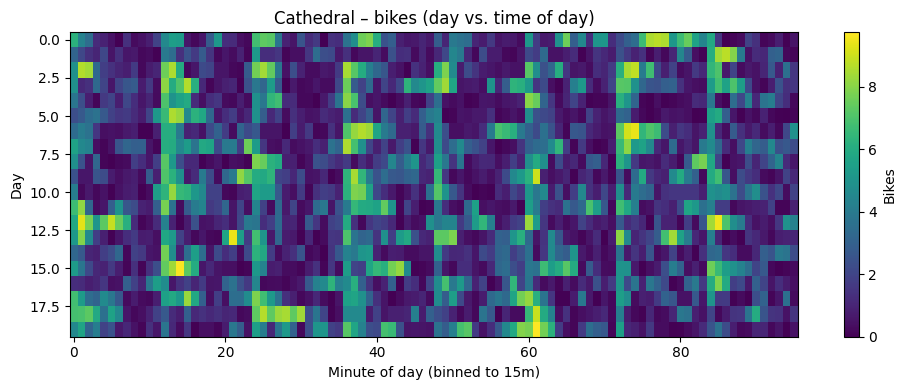

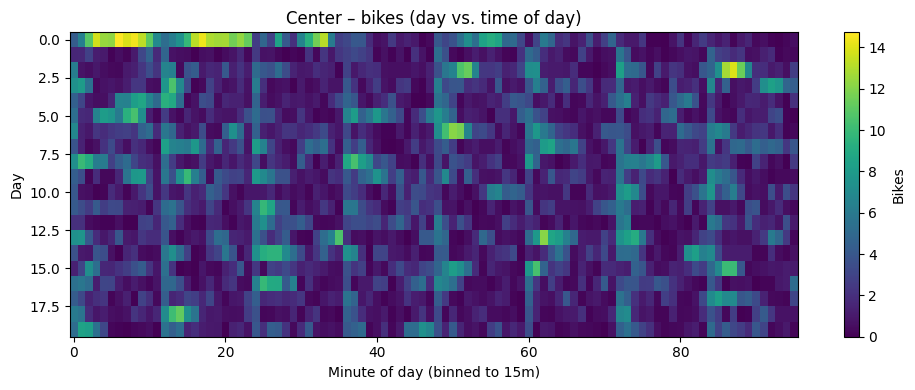

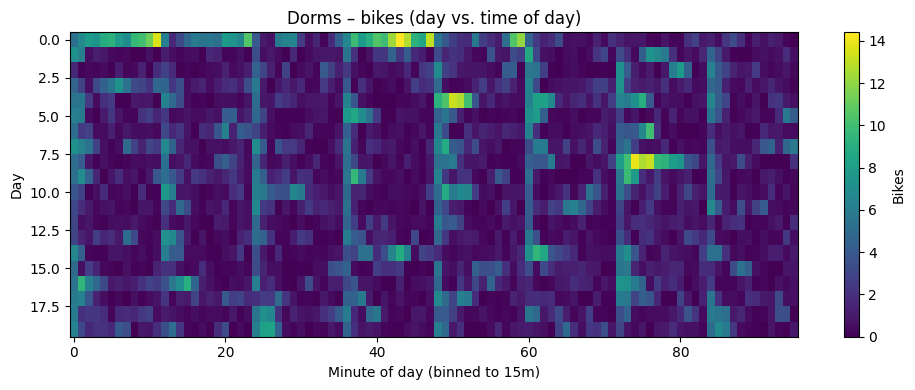

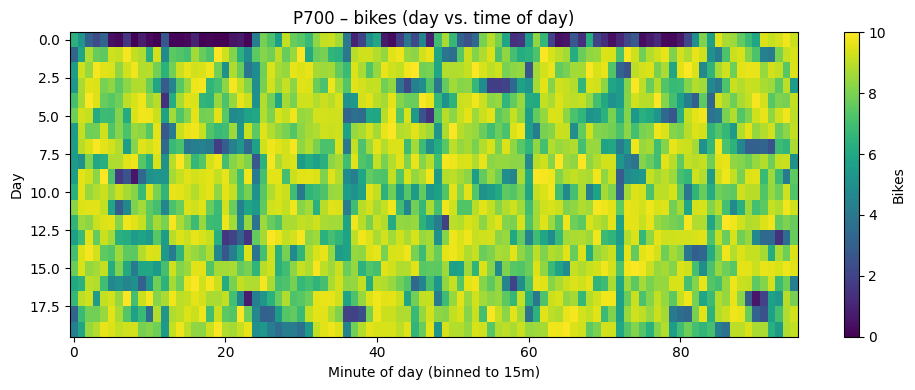

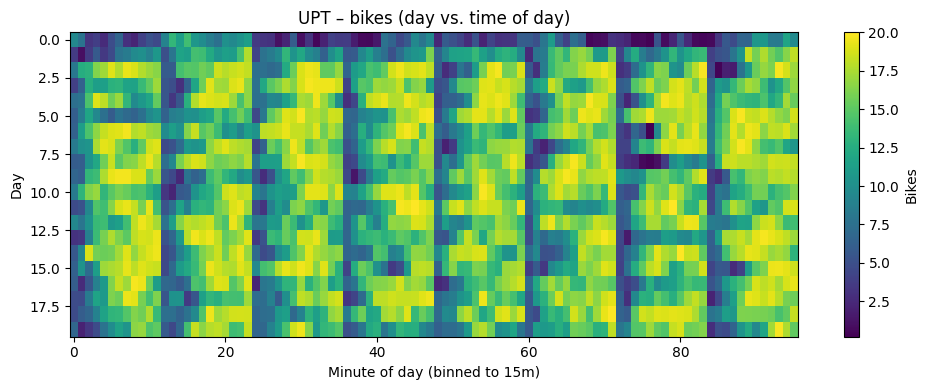

In [40]:
import math
import random
import simpy
from enum import Enum


class BikeStatus(Enum):
    STANDBY = "standby"
    ACTIVE = "active"
    DAMAGED = "damaged"
    OUT_OF_SERVICE = "out_of_service"


class Logs:
    def __init__(self, env, all_stations):
        self.env = env
        self.all_stations = all_stations
        self.unhappy_taking_customers = []
        self.unhappy_giving_customers = []
        self.bike_movements = []
        self.bikes_per_station_history = {station: [] for station in all_stations}
        self.bikes_in_maintenance = []

    def bikeTaken(self, env, bike, src):
        bikeData = {}
        bikeData[env.now] = f"Bike {bike.id} picked from " + src.name
        self.bike_movements.append(bikeData)

    def bikeDropped(self, env, bike, dest, note: str = ""):
        bikeData = {}
        bikeData[env.now] = f"Bike {bike.id} dropped to " + dest.name + note
        self.bike_movements.append(bikeData)
        if (note == " after repairs."):
            self.bikes_in_maintenance.remove(bike.id)

    def bikeBrokeDown(self, env, bike):
        bikeData = {}
        bikeData[env.now] = f"Bike {bike.id} was taken to the repair shop."
        self.bike_movements.append(bikeData)
        self.bikes_in_maintenance.append(bike.id)

    def bikeDamagedBeyondRepair(self, env, bike):
        bikeData = {}
        bikeData[env.now] = f"Bike {bike.id} is too damaged to be repaired. Set to OUT_OF_SERVICE."
        self.bike_movements.append(bikeData)
        self.bikes_in_maintenance.remove(bike.id)

    def unhappyTriedTaking(self, env):
        self.unhappy_taking_customers.append(env.now)

    def unhappyTriedDropping(self, env):
        self.unhappy_giving_customers.append(env.now)

    def log_bikes_per_station(self):
        while True:
            for station in self.all_stations:
                self.bikes_per_station_history[station].append((self.env.now, station.getNumberOfAvailableBikes()))
            yield self.env.timeout(1)
            



class Bike:
    def __init__(self, id):
        self.id = id
        self.status = BikeStatus.STANDBY

    def setBikeStatus(self, new_status):
        self.status = new_status

    def __str__(self):
        return f"Bike {self.id:2d}, Status - {self.status}"



class Fleet:
    def __init__(self, env):
        self.env = env
        self.next_id = 1
        self.bikes = {}

    def createBike(self):
        bike = Bike(self.next_id)
        self.bikes[self.next_id] = bike
        self.next_id += 1
        return bike



class Station:
    def __init__(self, env, name, capacity, init_bikes, bike_fleet):
        self.env = env
        self.name = name
        self.capacity = capacity
        self.bikes = simpy.Store(env, capacity=capacity)
        for i in range(init_bikes):
            self.bikes.put(bike_fleet.createBike())

    def isBikeAvailable(self):
        return len(self.bikes.items) > 0

    def isSpaceAvailable(self):
        return len(self.bikes.items) < self.capacity
    
    def getNumberOfSpacesAvailable(self):
        return self.capacity - len(self.bikes.items)
    
    def getNumberOfAvailableBikes(self):
        return len(self.bikes.items)

    def takeBike(self):
        bike = self.bikes.get()
        return bike

    def returnBike(self, bike):
        self.bikes.put(bike)



class Service():
    def __init__(self, env, all_stations, logs, repair_time, repair_chance, scrapped_chance):
        self.env = env
        self.logs = logs
        self.all_stations = all_stations
        self.repair_time = repair_time
        self.repair_chance = repair_chance
        self.scrapped_chance = scrapped_chance
        self.damaged_bikes = simpy.Store(env)


    def takeDamagedBike(self, bike):
        self.damaged_bikes.put(bike)


    def returnRepairedBike(self, bike):
        for i in range(len(self.all_stations)):
            if self.all_stations[i].isSpaceAvailable():
                self.all_stations[i].returnBike(bike)
                bike.setBikeStatus(BikeStatus.STANDBY)
                self.logs.bikeDropped(self.env, bike, self.all_stations[i], " after repairs.")
                return


    def repairBikes(self):
        while (True):
            bike = yield self.damaged_bikes.get()

            while (True):
                yield self.env.timeout(self.repair_time)
                if (random.uniform(0,1) < self.repair_chance):
                    self.returnRepairedBike(bike)
                    break

                if (random.uniform(0,1) < self.scrapped_chance):
                    bike.setBikeStatus(BikeStatus.OUT_OF_SERVICE)
                    self.logs.bikeDamagedBeyondRepair(self.env, bike)
                    break           

                yield self.env.timeout(5)         
            
            yield self.env.timeout(10)
            
            


class Simulations:
    def __init__(self, env, all_stations, time_slots, bike_fleet, sim_minutes, rebalance_interval_in_minutes, 
                 repair_time = 30, repair_chance = 0.9, scrapped_chance = 0.1, trip_time = (2, 6)):
        self.env = env
        self.all_stations = all_stations
        self.trip_time = trip_time
        self.sim_minutes = sim_minutes
        self.rebalance_interval_in_minutes = rebalance_interval_in_minutes
        self.time_slots = time_slots
        self.prob_matrix = time_slots[0]["prob_matrix"]
        self.desired_distribution = self.stations_bike_distribution(self.prob_matrix)
        self.bike_fleet = bike_fleet
        self.logs = Logs(env, all_stations)
        self.ServiceStation = Service(env, all_stations, self.logs, repair_time, repair_chance, scrapped_chance)
        

    def stations_bike_distribution(self, prob_matrix):
        from_dict = {}
        total = 0.0
        for (src, _dst), p in prob_matrix.items():
            from_dict[src] = from_dict.get(src, 0.0) + p
            total += p
        if total == 0:
            return {src: 0.0 for src in from_dict}
        return {src: (value / total) for src, value in from_dict.items()}
    

    def rebalancing(self):
        while(True):
            total_bikes_on_standby = sum(
                1 for bike in self.bike_fleet.bikes.values() if bike.status == BikeStatus.STANDBY
            )
            
            quotas = [p * total_bikes_on_standby for p in self.desired_distribution.values()]
            floors = [math.floor(q) for q in quotas]
            allocated = sum(floors)

            leftover = total_bikes_on_standby - allocated
            if leftover > 0:
                # (remainder, original_index); sort by largest remainder, then by index (stable tiebreaker)
                remainders = [(quotas[i] - floors[i], i) for i in range(len(self.all_stations))]
                remainders.sort(key=lambda x: (-x[0], x[1]))
                for k in range(leftover):
                    floors[remainders[k][1]] += 1

            # Keep your original structure: list of {station: count}
            desired_distribution_number_of_bikes = [{self.all_stations[i]: floors[i]} for i in range(len(self.all_stations))]
                                        #could have gone for this tho {station: count}

            #create a list with the differences between the desired number of bikes and the current number of bikes for each station
            difference_in_bikes = []
            for station in self.all_stations:
                current_bikes = station.getNumberOfAvailableBikes()
                desired_bikes = desired_distribution_number_of_bikes[self.all_stations.index(station)][station]
                difference_in_bikes.append({station: current_bikes - desired_bikes})

            #sort the list in descending order based on the difference
            difference_in_bikes.sort(reverse=True, key=lambda x: list(x.values())[0])
            #rebalance the bikes based on the difference
            for diff in difference_in_bikes:
                station = list(diff.keys())[0]
                difference = diff[station]
                if difference > 0:
                    #station has more bikes than desired, move bikes to stations with less bikes
                    for target_diff in difference_in_bikes[::-1]:  # [start:stop:step], iterate backwards
                        target_station = list(target_diff.keys())[0]  #the more /pythonic/ way would be         target_station = next(iter(target_diff))
                        target_difference = target_diff[target_station]
                        if target_difference < 0:
                            #target station has less bikes than desired, move bikes from station to target_station
                            bikes_to_move = min(difference, -target_difference, target_station.getNumberOfSpacesAvailable())
                            for _ in range(bikes_to_move):
                                bike = yield station.takeBike()
                                self.logs.bikeTaken(self.env, bike, station)
                                target_station.returnBike(bike)
                                self.logs.bikeDropped(self.env, bike, target_station, " (rebalanced).")
                                difference -= 1
                                target_difference += 1
                                #update the differences in the lists
                                diff[station] = difference
                                target_diff[target_station] = target_difference
                                if difference == 0:
                                    break
                        if difference == 0:
                            break

            yield self.env.timeout(self.rebalance_interval_in_minutes)


    def initiateBikeTrip(self, env, src_station, dest_station, all_stations, logs, trip_time, break_down_chance = 0.01):
        if src_station.isBikeAvailable():
            bike = yield src_station.takeBike()
            logs.bikeTaken(env, bike, src_station)
            bike.setBikeStatus(BikeStatus.ACTIVE)
        else:
            logs.unhappyTriedTaking(env)
            return
 
        yield self.env.timeout(random.randint(*trip_time))   #unpacks the touple into separate arguments

        if random.uniform(0, 1) < break_down_chance:
            bike.setBikeStatus(BikeStatus.DAMAGED)
            self.ServiceStation.takeDamagedBike(bike)
            logs.bikeBrokeDown(env, bike)
            return

        if dest_station.isSpaceAvailable():
            dest_station.returnBike(bike)
            bike.setBikeStatus(BikeStatus.STANDBY)
            logs.bikeDropped(env, bike, dest_station)
        else:
            logs.unhappyTriedDropping(env)
            for i in range(len(all_stations)):
                if all_stations[i].isSpaceAvailable():
                    all_stations[i].returnBike(bike)
                    bike.setBikeStatus(BikeStatus.STANDBY)
                    logs.bikeDropped(env, bike, all_stations[i])
                    return      # o statie cu loc SIGUR gaseste
                
        
    def runTrips(self):
        while True:
            for (from_station, to_station), prob in self.prob_matrix.items():
                if random.uniform(0, 1) < prob:
                    self.env.process(self.initiateBikeTrip(self.env, from_station, to_station, self.all_stations, self.logs, self.trip_time))
            yield self.env.timeout(1)


    def adjust_prob_matrix(self):
        while True:
            t = self.env.now
            for slot in self.time_slots:
                if slot["start"] <= t <= slot["end"]:
                    self.prob_matrix = slot["prob_matrix"]
                    break
            self.desired_distribution = self.stations_bike_distribution(self.prob_matrix)
            yield self.env.timeout(60)


    def runSim(self):
        self.env.process(self.runTrips())
        self.env.process(self.logs.log_bikes_per_station())
        self.env.process(self.adjust_prob_matrix())
        self.env.process(self.ServiceStation.repairBikes())
        self.env.process(self.rebalancing())

        self.env.run(until=self.sim_minutes)
        return self.logs




env = simpy.Environment()

bike_fleet = Fleet(env)
upt_station = Station(env, "UPT", capacity=20, init_bikes=10, bike_fleet = bike_fleet)
center_station = Station(env, "Center", capacity=15, init_bikes=7, bike_fleet = bike_fleet)
cathedral_station = Station(env, "Cathedral", capacity=10, init_bikes=5, bike_fleet = bike_fleet)
dorms_station = Station(env, "Dorms", capacity=20, init_bikes=10, bike_fleet = bike_fleet)
p700_station = Station(env, "P700", capacity=10, init_bikes=4, bike_fleet = bike_fleet)

all_stations = [upt_station, center_station, cathedral_station, dorms_station, p700_station]

time_slots = [
    {
        "name": "after_midnight",
        "start": 0,
        "end": 6*60-1,
        "prob_matrix": {
            (upt_station, center_station): 0.13,
            (upt_station, cathedral_station): 0.02,
            (upt_station, dorms_station): 0.08,
            (upt_station, p700_station): 0.12,
            (center_station, upt_station): 0.02,
            (center_station, cathedral_station): 0.13,
            (center_station, dorms_station): 0.02,
            (center_station, p700_station): 0.01,
            (cathedral_station, upt_station): 0.11,
            (cathedral_station, center_station): 0.03,
            (cathedral_station, dorms_station): 0.21,
            (cathedral_station, p700_station): 0.01,
            (dorms_station, upt_station): 0.11,
            (dorms_station, center_station): 0.05,
            (dorms_station, cathedral_station): 0.04,
            (dorms_station, p700_station): 0.01,
            (p700_station, upt_station): 0.06,
            (p700_station, center_station): 0.09,
            (p700_station, cathedral_station): 0.04,
            (p700_station, dorms_station): 0.04,            
        }
    },
    {
        "name": "morning",
        "start": 6*60,
        "end": 10*60-1,
        "prob_matrix": {
            (upt_station, center_station): 0.21,
            (upt_station, cathedral_station): 0.18,
            (upt_station, dorms_station): 0.31,
            (upt_station, p700_station): 0.11,
            (center_station, upt_station): 0.12,
            (center_station, cathedral_station): 0.19,
            (center_station, dorms_station): 0.11,
            (center_station, p700_station): 0.26,
            (cathedral_station, upt_station): 0.19,
            (cathedral_station, center_station): 0.15,
            (cathedral_station, dorms_station): 0.15,
            (cathedral_station, p700_station): 0.11,
            (dorms_station, upt_station): 0.13,
            (dorms_station, center_station): 0.22,
            (dorms_station, cathedral_station): 0.12,
            (dorms_station, p700_station): 0.22,
            (p700_station, upt_station): 0.11,
            (p700_station, center_station): 0.15,
            (p700_station, cathedral_station): 0.1,
            (p700_station, dorms_station): 0.12,      
        }
    },
    {
        "name": "midday",
        "start": 10*60,
        "end": 16*60-1,
        "prob_matrix": {
            (upt_station, center_station): 0.11,
            (upt_station, cathedral_station): 0.15,
            (upt_station, dorms_station): 0.16,
            (upt_station, p700_station): 0.16,
            (center_station, upt_station): 0.2,
            (center_station, cathedral_station): 0.15,
            (center_station, dorms_station): 0.13,
            (center_station, p700_station): 0.13,
            (cathedral_station, upt_station): 0.11,
            (cathedral_station, center_station): 0.12,
            (cathedral_station, dorms_station): 0.23,
            (cathedral_station, p700_station): 0.15,
            (dorms_station, upt_station): 0.15,
            (dorms_station, center_station): 0.12,
            (dorms_station, cathedral_station): 0.1,
            (dorms_station, p700_station): 0.14,
            (p700_station, upt_station): 0.21,
            (p700_station, center_station): 0.11,
            (p700_station, cathedral_station): 0.13,
            (p700_station, dorms_station): 0.12,
        }
    },
    {
        "name": "evening",
        "start": 16*60,
        "end": 20*60-1,
        "prob_matrix": {
            (upt_station, center_station): 0.29,
            (upt_station, cathedral_station): 0.34,
            (upt_station, dorms_station): 0.22,
            (upt_station, p700_station): 0.2,
            (center_station, upt_station): 0.16,
            (center_station, cathedral_station): 0.46,
            (center_station, dorms_station): 0.23,
            (center_station, p700_station): 0.14,
            (cathedral_station, upt_station): 0.18,
            (cathedral_station, center_station): 0.22,
            (cathedral_station, dorms_station): 0.16,
            (cathedral_station, p700_station): 0.36,
            (dorms_station, upt_station): 0.21,
            (dorms_station, center_station): 0.32,
            (dorms_station, cathedral_station): 0.18,
            (dorms_station, p700_station): 0.26,
            (p700_station, upt_station): 0.27,
            (p700_station, center_station): 0.24,
            (p700_station, cathedral_station): 0.29,
            (p700_station, dorms_station): 0.19,       
        }
    },
    {
        "name": "before_midnight",
        "start": 20*60,
        "end": 24*60-1,
        "prob_matrix": {
            (upt_station, center_station): 0.06,
            (upt_station, cathedral_station): 0.08,
            (upt_station, dorms_station): 0.1,
            (upt_station, p700_station): 0.1,
            (center_station, upt_station): 0.15,
            (center_station, cathedral_station): 0.12,
            (center_station, dorms_station): 0.05,
            (center_station, p700_station): 0.08,
            (cathedral_station, upt_station): 0.07,
            (cathedral_station, center_station): 0.12,
            (cathedral_station, dorms_station): 0.06,
            (cathedral_station, p700_station): 0.18,
            (dorms_station, upt_station): 0.1,
            (dorms_station, center_station): 0.07,
            (dorms_station, cathedral_station): 0.09,
            (dorms_station, p700_station): 0.19,
            (p700_station, upt_station): 0.06,
            (p700_station, center_station): 0.06,
            (p700_station, cathedral_station): 0.07,
            (p700_station, dorms_station): 0.08,
        }
    }
]

sim = Simulations(env, all_stations, time_slots, bike_fleet, sim_minutes = 20*24*60, rebalance_interval_in_minutes = 3*60)
final_logs = sim.runSim()

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import defaultdict

# --- Build a tidy DataFrame from your log ---
rows = []
for station, hist in final_logs.bikes_per_station_history.items():
    name = station if isinstance(station, str) else station.name
    for t, c in hist:
        rows.append((name, int(t), int(c)))
df = pd.DataFrame(rows, columns=["station","t","count"])

# If you ran multiple days, derive day index & minute-of-day
df["day"] = df["t"] // (24*60)
df["min_of_day"] = df["t"] % (24*60)

# Optional downsample to 15-minute buckets for smoother visuals
bin_size = 15
df["bin"] = (df["min_of_day"] // bin_size) * bin_size

# --- Heatmap: day (rows) x time-of-day (cols) ---
for st in sorted(df["station"].unique()):
    pivot = df[df["station"]==st].pivot_table(
        index="day", columns="bin", values="count", aggfunc="mean", fill_value=np.nan
    ).values
    plt.figure(figsize=(10, 4))
    plt.imshow(pivot, aspect="auto", interpolation="nearest")
    plt.title(f"{st} – bikes (day vs. time of day)")
    plt.xlabel(f"Minute of day (binned to {bin_size}m)")
    plt.ylabel("Day")
    plt.colorbar(label="Bikes")
    plt.tight_layout()
    plt.show()